In [25]:
import pymc as pm
import arviz as az
import numpy as np
import scipy
import scipy.stats as stats
from scipy.optimize import minimize
import pandas as pd
import matplotlib.pyplot as plt
import numdifftools as nd
import pymc as pm
import arviz as az

### Treatment sample generation

In [26]:
rng = np.random.default_rng(seed=42)
treatment = rng.binomial(n=1, p=0.5, size=1000)

### Fungi sample generation

In [27]:
fungi = rng.binomial(n=1, p=0.5, size=1000)

## Height calculation

In [28]:
mu = 100 + 10 * treatment - 10 * fungi
sigma = 5

height = rng.normal(loc=mu, scale=sigma)

In [29]:
df = pd.DataFrame(
    {
        "treatment": treatment,
        "fungi": fungi,
        "height": height,
    }
)

print(df.shape)
df.head()

(1000, 3)


,treatment,fungi,height
0,1,0,104.877355
1,0,0,104.540314
2,1,0,103.986517
3,1,0,108.568169
4,0,1,87.069742


In [46]:
print(df[["treatment", "height", "fungi"]].corr().to_string())

           treatment    height     fungi
treatment   1.000000  0.587414 -0.012061
height      0.587414  1.000000 -0.575519
fungi      -0.012061 -0.575519  1.000000


In [31]:
df_conditioned = df[(df["height"] > 98) & (df["height"] < 102)]

In [32]:
print(df_conditioned[["treatment", "fungi"]].corr().to_string())

           treatment     fungi
treatment   1.000000  0.731991
fungi       0.731991  1.000000


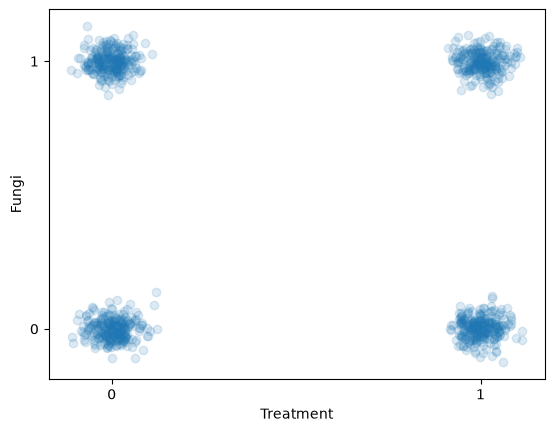

In [33]:
plt.scatter(
    df["treatment"] + rng.normal(0, 0.04, len(df)),
    df["fungi"] + rng.normal(0, 0.04, len(df)),
    alpha=0.15,
)
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.xlabel("Treatment")
plt.ylabel("Fungi")
plt.show()

In [37]:
df["height"] = (df["height"] - 100) / 10

In [43]:
with pm.Model() as model_m:
    alpha = pm.Normal("alpha", 0, 1)
    beta_t = pm.Normal("beta_t", 0, 1)
    log_odds = alpha + beta_t * df["treatment"].to_numpy()
    fungi = pm.Bernoulli(
        "fungi",
        logit_p=log_odds,
        observed=df["fungi"].to_numpy(),
    )

    trace_m = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_t]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 9 seconds.


In [39]:
with pm.Model() as model_m:
    alpha = pm.Normal("alpha", 0, 1)
    beta_t = pm.Normal("beta_t", 0, 1)
    beta_h = pm.Normal("beta_h", 0, 1)
    log_odds = (
        alpha
        + beta_t * df["treatment"].to_numpy()
        + beta_h * df["height"].to_numpy()
    )
    fungi = pm.Bernoulli(
        "fungi",
        logit_p=log_odds,
        observed=df["fungi"].to_numpy(),
    )

    trace_c = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_t, beta_h]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.


In [44]:
print("Model Marginal:")
print(az.summary(trace_m)[["mean", "sd"]])

print("Model Conditional:")
print(az.summary(trace_c)[["mean", "sd"]])

Model Marginal:
         mean     sd
alpha   0.002  0.088
beta_t -0.048  0.126
Model Conditional:
         mean     sd
alpha  -1.623  0.156
beta_t  3.375  0.265
beta_h -3.496  0.202
